# Río Mana · Análisis científico de granulometría superficial
**SfM + SegmentEveryGrain · bitácora reproducible (CPU, Google Colab)**

Este cuaderno analiza exclusivamente resultados ya exportados. No ejecuta U-Net ni SAM. Las cifras y figuras se calculan al ejecutar con los datos reales en Drive; **no se inventan resultados**. Sistema de referencia: **EPSG:32619**. Las dimensiones de los clastos son **proyecciones 2D**; no equivalen automáticamente a los ejes sedimentológicos medidos en terreno.

**Alcance:** muestra parcial y no necesariamente aleatoria de teselas. No extrapolar percentiles ni densidades a toda la llanura sin completar o justificar la cobertura. Los percentiles son **por conteo de clastos**, no por masa.

## 1 · Preparación y directorios

In [ ]:
# En Colab, ejecutar una sola vez. No requiere GPU.
%pip -q install geopandas pyogrio shapely rasterio scipy seaborn


In [1]:
from pathlib import Path
import json, re, warnings
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display

try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    pass

BASE = Path('/content/drive/MyDrive/gravas_mana/resultados_completo')
OUT = BASE / 'analisis_cientifico'
FIG = OUT / 'figuras'
TAB = OUT / 'tablas'
for d in (OUT, FIG, TAB): d.mkdir(parents=True, exist_ok=True)
CRS = 'EPSG:32619'
# Modificar si se decide una unidad espacial distinta:
CELDA_M = 1.0
# Exclusión solo para análisis de sensibilidad, NO eliminación irreversible:
EXCLUIR_BORDES = True
plt.rcParams.update({'figure.dpi': 120, 'savefig.dpi': 250,
                     'axes.spines.top': False, 'axes.spines.right': False})

def guardar(nombre):
    plt.savefig(FIG / f'{nombre}.png', bbox_inches='tight', dpi=250)
    plt.savefig(FIG / f'{nombre}.pdf', bbox_inches='tight')
    plt.show()

assert BASE.exists(), f'No existe la carpeta: {BASE}'
print('Resultados:', BASE, '\nExportaciones:', OUT)


Mounted at /content/drive
Resultados: /content/drive/MyDrive/gravas_mana/resultados_completo 
Exportaciones: /content/drive/MyDrive/gravas_mana/resultados_completo/analisis_cientifico


## 2 · Auditoría de cobertura y estado de las teselas
No confundir `sin_datos` con `sin_semillas`: la segunda etiqueta significa ausencia de detecciones, no ausencia real de clastos.

In [2]:
carpetas = sorted(p for p in BASE.glob('x*_y*') if p.is_dir())
filas = []
for p in carpetas:
    reg = p / 'registro.json'
    try:
        d = json.loads(reg.read_text()) if reg.exists() else {}
    except (OSError, json.JSONDecodeError):
        d = {}
    m = re.fullmatch(r'x(\d+)_y(\d+)', p.name)
    filas.append({'tesela': p.name, 'x_pixel': int(m[1]) if m else np.nan,
                  'y_pixel': int(m[2]) if m else np.nan,
                  'estado': d.get('estado', 'sin_registro'),
                  'ok': (p / 'completado.ok').exists(),
                  'csv': (p / 'mediciones.csv').exists(),
                  'geojson': (p / 'granos_utm.geojson').exists(),
                  'png': (p / 'segmentacion.png').exists(),
                  'semillas': d.get('semillas', np.nan),
                  'mascaras': d.get('mascaras', np.nan),
                  'n_granos_registro': d.get('granos_conservados', np.nan),
                  'segundos': d.get('segundos', np.nan)})
audit = pd.DataFrame(filas)
if audit.empty: raise ValueError('No se encontraron carpetas de teselas')
print('Estados:'); display(audit.estado.value_counts(dropna=False).rename_axis('estado').to_frame('n'))
print('Archivos:'); display(audit[['ok','csv','geojson','png']].sum().to_frame('n'))
audit.to_csv(TAB / 'auditoria_completa.csv', index=False)
# No todas las teselas tienen dimensiones 1024x1024 en el borde del mosaico.
# La cobertura efectiva requiere máscaras de nodata o revisión de cada tesela.


Estados:


,n
estado,
completada,177
sin_datos,57
sin_semillas,2
sin_registro,1


Archivos:


,n
ok,236
csv,177
geojson,177
png,177


## 3 · Leer mediciones y verificar unidades
Las métricas originales `area`, `major_axis_length` y `minor_axis_length` proceden de SegmentEveryGrain. Se comprobará que las unidades sean m² y m respectivamente mediante los rangos observados y la escala del worldfile.

In [3]:
csvs = sorted(BASE.glob('x*_y*/mediciones.csv'))
tablas, errores_csv = [], []
for p in csvs:
    try:
        if p.stat().st_size == 0:
            errores_csv.append((p.parent.name, 'vacío')); continue
        d = pd.read_csv(p)
        if d.empty: continue
        d['archivo_origen'] = p.parent.name
        tablas.append(d)
    except Exception as e:
        errores_csv.append((p.parent.name, str(e)))
if not tablas: raise ValueError('No hay mediciones legibles')
datos = pd.concat(tablas, ignore_index=True)
assert {'id_grano','tesela','area','major_axis_length','minor_axis_length','x_utm','y_utm'}.issubset(datos.columns)
duplicados = int(datos.id_grano.duplicated().sum())
if duplicados:
    warnings.warn(f'{duplicados} ID duplicados; revisar antes de analizar')
    datos = datos.drop_duplicates('id_grano')
for c in ['area','perimeter','major_axis_length','minor_axis_length','x_utm','y_utm']:
    if c in datos: datos[c] = pd.to_numeric(datos[c], errors='coerce')
datos['toca_borde'] = datos['toca_borde'].astype(str).str.lower().eq('true') if 'toca_borde' in datos else False
datos['a_mm'] = datos.major_axis_length * 1000
datos['b_mm'] = datos.minor_axis_length * 1000
datos['area_mm2'] = datos.area * 1e6
datos['diametro_equiv_mm'] = 2 * np.sqrt(datos.area.clip(lower=0) / np.pi) * 1000
datos['elongacion'] = datos.minor_axis_length / datos.major_axis_length.replace(0,np.nan)
if 'perimeter' in datos:
    datos['circularidad'] = 4*np.pi*datos.area / datos.perimeter.pow(2).replace(0,np.nan)
valido = (datos[['area','a_mm','b_mm']].notna().all(axis=1) &
          (datos.area > 0) & (datos.b_mm > 0) & (datos.a_mm >= datos.b_mm))
datos['qc_geometria'] = valido
print('Filas:',len(datos),'| geométricamente válidas:',int(valido.sum()),
      '| bordes:',int(datos.toca_borde.sum()),'| CSV vacíos/ilegibles:',len(errores_csv))
display(datos[['area','a_mm','b_mm','diametro_equiv_mm','elongacion']].describe(percentiles=[.05,.5,.95,.99]))
if errores_csv: display(pd.DataFrame(errores_csv,columns=['tesela','motivo']))
datos.to_csv(TAB / 'mediciones_derivadas_todas.csv', index=False)


Filas: 15432 | geométricamente válidas: 15432 | bordes: 721 | CSV vacíos/ilegibles: 2


,area,a_mm,b_mm,diametro_equiv_mm,elongacion
count,15432.000000,15432.000000,15432.000000,15432.000000,15432.000000
mean,0.007342,93.446496,56.032442,68.419869,0.637649
std,0.024382,99.256962,59.487578,68.313433,0.167605
min,0.000100,11.724919,8.104911,11.286806,0.029872
5%,0.000333,24.654854,16.334555,20.594494,0.348032
50%,0.001667,61.269266,36.527296,46.076109,0.648512
95%,0.029727,269.410766,162.255746,194.549124,0.893478
99%,0.100140,503.725241,303.681855,357.074668,0.949714
max,0.558937,1345.186960,914.127365,843.600137,0.999347


,tesela,motivo
0,x04480_y00000,No columns to parse from file
1,x18816_y02688,No columns to parse from file


## 4 · Subconjuntos y control de calidad
**No eliminar automáticamente valores extremos:** pueden ser bloques reales o máscaras fusionadas. El conjunto principal excluye geometrías imposibles y, opcionalmente, objetos marcados `toca_borde`. La comparación con/sin bordes se informa explícitamente.

,conjunto,n
0,todas,15432
1,geométricamente válidas,15432
2,principal,14711


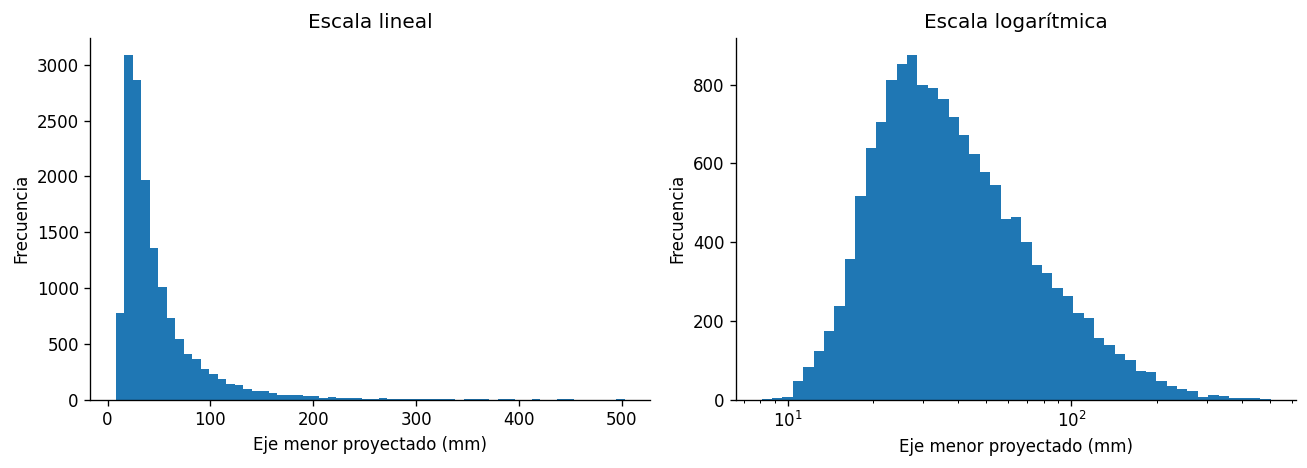

In [4]:
base_qc = datos.loc[datos.qc_geometria].copy()
principal = base_qc.loc[~base_qc.toca_borde].copy() if EXCLUIR_BORDES else base_qc.copy()
if principal.empty: raise ValueError('El filtro dejó la muestra vacía')
res_qc = pd.DataFrame({'conjunto':['todas','geométricamente válidas','principal'],
                       'n':[len(datos),len(base_qc),len(principal)]})
display(res_qc)
res_qc.to_csv(TAB/'control_calidad_resumen.csv',index=False)
fig, ax = plt.subplots(1,2,figsize=(11,4))
ax[0].hist(principal.b_mm,bins=60); ax[0].set(xlabel='Eje menor proyectado (mm)',ylabel='Frecuencia',title='Escala lineal')
ax[1].hist(principal.b_mm,bins=np.geomspace(max(principal.b_mm.min(),.1),principal.b_mm.max(),50));ax[1].set_xscale('log')
ax[1].set(xlabel='Eje menor proyectado (mm)',ylabel='Frecuencia',title='Escala logarítmica')
plt.tight_layout(); guardar('01_histogramas_eje_menor')


## 5 · Distribución granulométrica por conteo
Se calculan D10, D16, D50, D84 y D90 como **cuantiles de la dimensión menor proyectada** (`minor_axis_length`), por número de objetos. No representan una distribución tamizada por masa. Los objetos no detectados generan sesgo de truncamiento hacia tamaños mayores.

,conjunto,n,D10_mm,D16_mm,D50_mm,D84_mm,D90_mm
0,principal,14711.0,18.583,20.872,35.149,74.506,94.143
1,con_bordes,15432.0,18.771,21.143,36.527,85.542,113.558


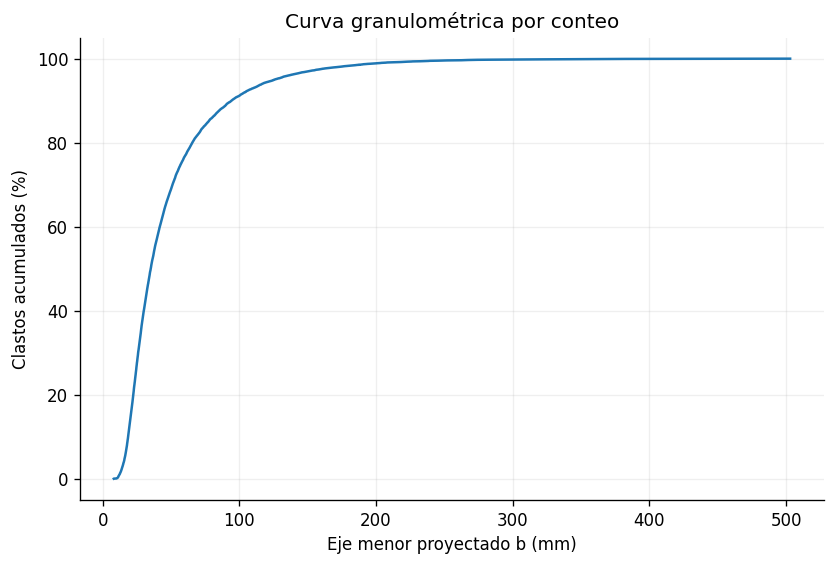

In [5]:
P = [.10,.16,.50,.84,.90]
def percentiles(df, variable='b_mm'):
    z = pd.to_numeric(df[variable],errors='coerce').dropna()
    z = z[z>0]
    out = {'n':len(z)}
    out.update({f'D{int(p*100)}_mm': float(z.quantile(p)) if len(z) else np.nan for p in P})
    return pd.Series(out)
res_gran = pd.DataFrame([{'conjunto':'principal',**percentiles(principal).to_dict()},
                         {'conjunto':'con_bordes',**percentiles(base_qc).to_dict()}])
display(res_gran.round(3))
res_gran.to_csv(TAB/'percentiles_conteo.csv',index=False)
orden = np.sort(principal.b_mm.to_numpy())
fig,ax=plt.subplots(figsize=(8,5))
ax.plot(orden,100*np.arange(1,len(orden)+1)/len(orden))
ax.set(xlabel='Eje menor proyectado b (mm)',ylabel='Clastos acumulados (%)',title='Curva granulométrica por conteo')
ax.grid(alpha=.2); guardar('02_curva_acumulada_conteo')


## 6 · Morfometría y relaciones entre ejes
La elongación es `b/a` de la elipse equivalente, no la esfericidad tridimensional. La circularidad puede ser sensible a la irregularidad del contorno y a la resolución.

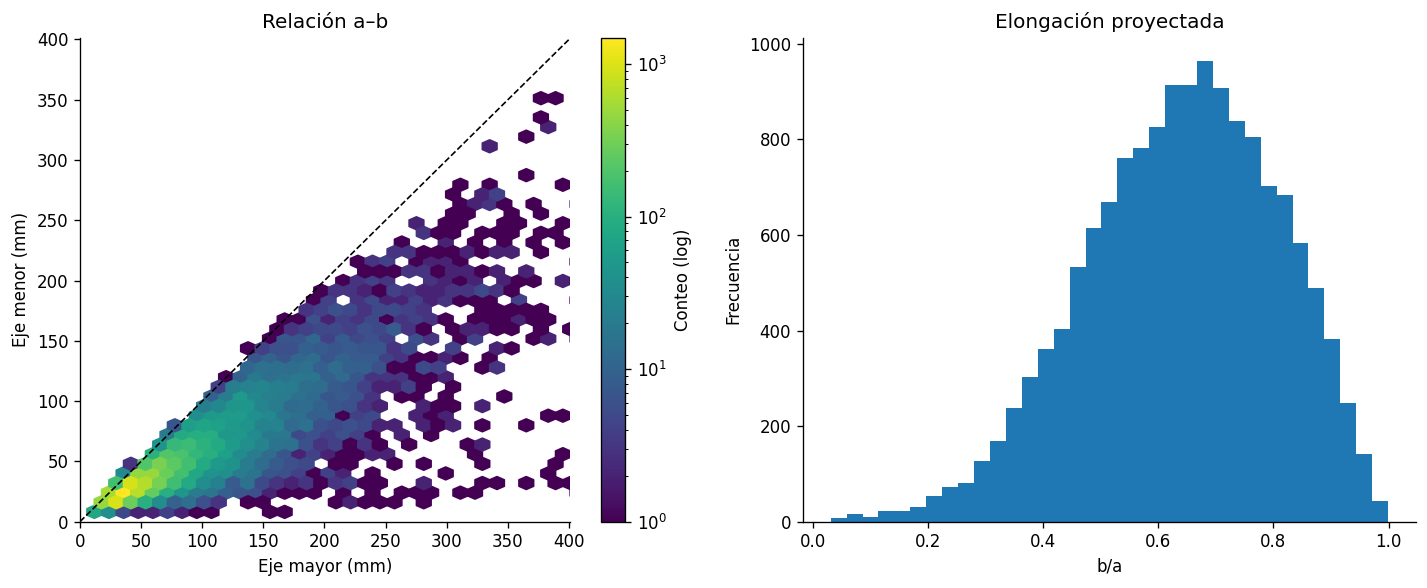

In [6]:
fig,ax=plt.subplots(1,2,figsize=(12,5))
hb=ax[0].hexbin(principal.a_mm,principal.b_mm,gridsize=55,mincnt=1,bins='log')
lim=max(principal.a_mm.quantile(.995),principal.b_mm.quantile(.995))
ax[0].plot([0,lim],[0,lim],'k--',lw=1)
ax[0].set(xlim=(0,lim),ylim=(0,lim),xlabel='Eje mayor (mm)',ylabel='Eje menor (mm)',title='Relación a–b')
fig.colorbar(hb,ax=ax[0],label='Conteo (log)')
ax[1].hist(principal.elongacion.dropna(),bins=35)
ax[1].set(xlabel='b/a',ylabel='Frecuencia',title='Elongación proyectada')
plt.tight_layout();guardar('03_morfometria')


## 7 · Distribución espacial de centroides y granulometría
El mapa de centroides muestra solo los objetos detectados. Las celdas de 1 m sirven para comparar zonas **dentro de la cobertura procesada**, no para inferir ausencia de clastos en celdas no procesadas. El conteo por celda NO es densidad por m² salvo que se calcule la superficie efectiva observada.

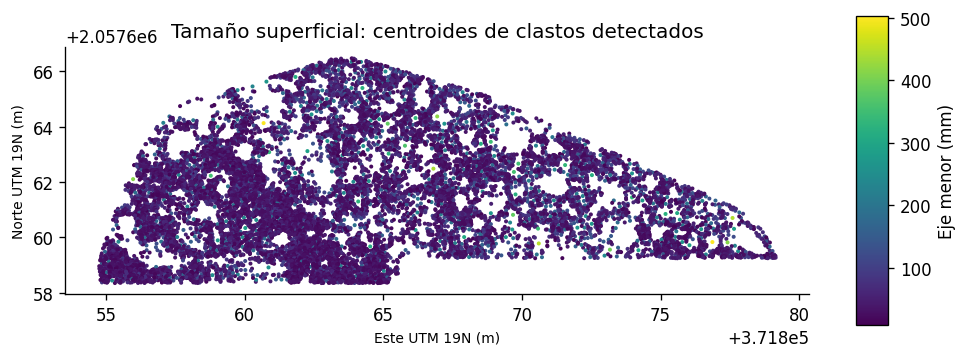

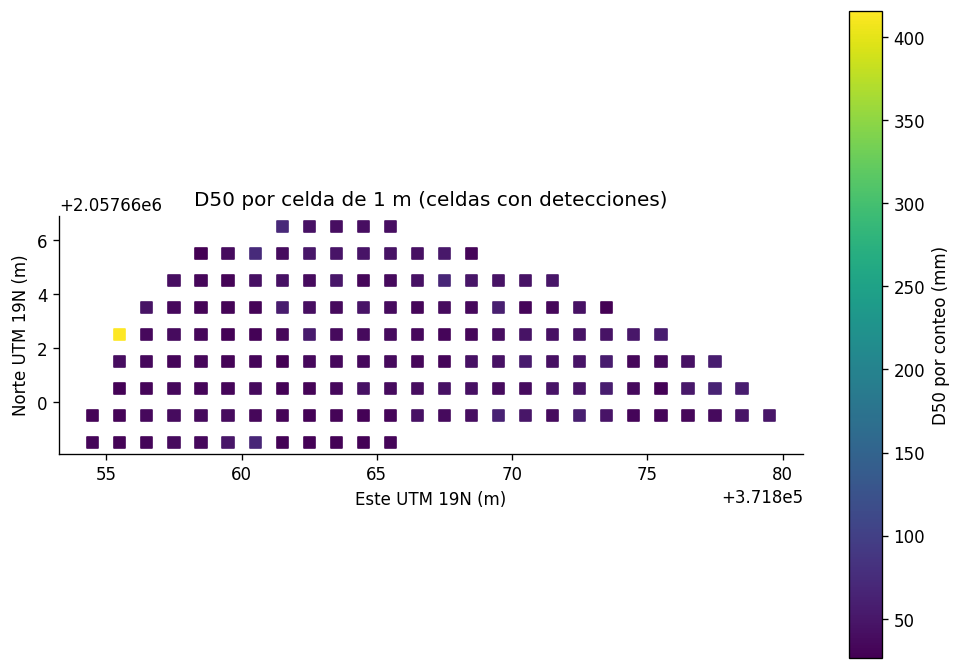

In [7]:
g = gpd.GeoDataFrame(principal.copy(),geometry=gpd.points_from_xy(principal.x_utm,principal.y_utm),crs=CRS)
g.to_file(OUT/'centroides_clastos.gpkg',layer='centroides',driver='GPKG')
fig,ax=plt.subplots(figsize=(10,7))
s=g.plot(ax=ax,column='b_mm',markersize=2,cmap='viridis',legend=True,
         legend_kwds={'label':'Eje menor (mm)'})
ax.set(xlabel='Este UTM 19N (m)',ylabel='Norte UTM 19N (m)',title='Tamaño superficial: centroides de clastos detectados')
ax.set_aspect('equal'); guardar('04_mapa_centroides')
# Malla anclada en coordenadas UTM enteras, estable al añadir teselas futuras.
g['celda_x'] = np.floor(g.x_utm/CELDA_M).astype(int)
g['celda_y'] = np.floor(g.y_utm/CELDA_M).astype(int)
agr = g.groupby(['celda_x','celda_y']).agg(n=('b_mm','size'),
    D50_mm=('b_mm','median'),D84_mm=('b_mm',lambda x:x.quantile(.84)),
    b_media_mm=('b_mm','mean'),elongacion_media=('elongacion','mean')).reset_index()
agr['x_centro']=(agr.celda_x+.5)*CELDA_M
agr['y_centro']=(agr.celda_y+.5)*CELDA_M
agr.to_csv(TAB/'resumen_celdas.csv',index=False)
fig,ax=plt.subplots(figsize=(10,7))
sc=ax.scatter(agr.x_centro,agr.y_centro,c=agr.D50_mm,s=45,cmap='viridis',marker='s')
plt.colorbar(sc,ax=ax,label='D50 por conteo (mm)')
ax.set_aspect('equal');ax.set(xlabel='Este UTM 19N (m)',ylabel='Norte UTM 19N (m)',title=f'D50 por celda de {CELDA_M:g} m (celdas con detecciones)')
guardar('05_mapa_D50_celdas')


## 8 · Exportar polígonos georreferenciados
La exportación de polígonos se realiza solo desde teselas terminadas y con GeoJSON legible. Puede llevar unos minutos en Drive. Si un archivo falla, se registra y no se pierde el resto.

In [8]:
capas=[]; errores_geo=[]
for p in sorted(BASE.glob('x*_y*/granos_utm.geojson')):
    if not (p.parent/'completado.ok').exists(): continue
    try:
        z=gpd.read_file(p)
        if z.empty: continue
        if z.crs is None: raise ValueError('GeoJSON sin CRS; no se asigna arbitrariamente')
        z=z.to_crs(CRS)
        z['tesela_archivo']=p.parent.name
        capas.append(z)
    except Exception as e:
        errores_geo.append((p.parent.name,str(e)))
if capas:
    poligonos=pd.concat(capas,ignore_index=True)
    if 'id_grano' in poligonos:
        poligonos=poligonos.drop_duplicates('id_grano')
    poligonos=gpd.GeoDataFrame(poligonos,geometry='geometry',crs=CRS)
    poligonos.to_file(OUT/'clastos_poligonos.gpkg',layer='clastos',driver='GPKG')
    print('Polígonos exportados:',len(poligonos))
else: print('Sin polígonos legibles')
if errores_geo: display(pd.DataFrame(errores_geo,columns=['tesela','error']).head(20))


Polígonos exportados: 15432


## 9 · Diagnóstico de teselas y rendimiento
Una tesela segmentada puede tener cero clastos conservados. El recuento de semillas no es el número de clastos. No se debe dividir el total de clastos por la superficie total del ortomosaico para obtener densidades.

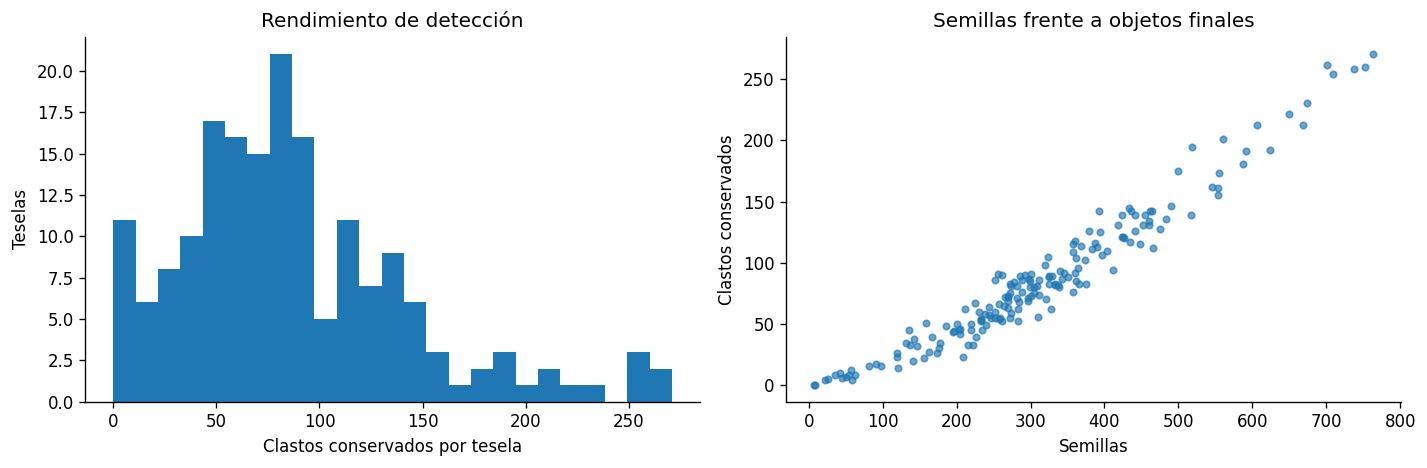

Mediana segundos/tesela completada: 47.971301222999955


In [9]:
segm=audit.loc[audit.estado.eq('completada')].copy()
fig,ax=plt.subplots(1,2,figsize=(12,4))
ax[0].hist(segm.n_granos_registro.dropna(),bins=25)
ax[0].set(xlabel='Clastos conservados por tesela',ylabel='Teselas',title='Rendimiento de detección')
ax[1].scatter(segm.semillas,segm.n_granos_registro,s=15,alpha=.65)
ax[1].set(xlabel='Semillas',ylabel='Clastos conservados',title='Semillas frente a objetos finales')
plt.tight_layout(); guardar('06_rendimiento_teselas')
print('Mediana segundos/tesela completada:',segm.segundos.median())


## 10 · Resumen automático y límites de inferencia

In [10]:
d50=float(principal.b_mm.median())
d84=float(principal.b_mm.quantile(.84))
resumen=(f'Se auditaron {len(audit)} carpetas: '
         f'{int((audit.estado=="completada").sum())} teselas segmentadas, '
         f'{int((audit.estado=="sin_datos").sum())} sin datos, '
         f'{int((audit.estado=="sin_semillas").sum())} sin semillas y '
         f'{int((audit.estado=="sin_registro").sum())} sin registro. '
         f'El conjunto contiene {len(datos):,} clastos exportados; '
         f'{len(principal):,} integran el subconjunto principal de calidad. '
         f'En este subconjunto, D50={d50:.1f} mm y D84={d84:.1f} mm '
         'para el eje menor proyectado y ponderación por número de clastos. '
         'Los resultados son provisionales y se limitan a las zonas procesadas; '
         'no se ha validado aún contra las mediciones manuales de 2019.')
print(resumen)
(OUT/'resumen_para_presentacion.txt').write_text(resumen,encoding='utf-8')
print('Figuras:',FIG,'\nTablas:',TAB)


Se auditaron 237 carpetas: 177 teselas segmentadas, 57 sin datos, 2 sin semillas y 1 sin registro. El conjunto contiene 15,432 clastos exportados; 14,711 integran el subconjunto principal de calidad. En este subconjunto, D50=35.1 mm y D84=74.5 mm para el eje menor proyectado y ponderación por número de clastos. Los resultados son provisionales y se limitan a las zonas procesadas; no se ha validado aún contra las mediciones manuales de 2019.
Figuras: /content/drive/MyDrive/gravas_mana/resultados_completo/analisis_cientifico/figuras 
Tablas: /content/drive/MyDrive/gravas_mana/resultados_completo/analisis_cientifico/tablas


## 11 · Antes de interpretar geomorfológicamente

- **Validación:** recuperar tabla y correspondencia espacial de los clastos medidos en 2019. Comparar ejes homólogos y calcular sesgo, MAE, RMSE, concordancia y gráficos de Bland–Altman; no equiparar automáticamente `major_axis_length` con el eje `a` de campo.
- **Cobertura:** generar un polígono de huella útil por tesela (excluyendo nodata) para densidades reales, mapas de ausencia y comparaciones entre sectores. Los centroides por sí solos no bastan.
- **Sesgos:** estudiar fallos por tamaño, objetos parcialmente ocluidos, fusiones y cortes de borde. La asignación por centroide entre teselas evita muchos duplicados, pero **no reconstruye máscaras cortadas**.
- **Estadística espacial:** definir unidades sedimentológicas y diseño de muestreo antes de contrastes o autocorrelación espacial. Los clastos cercanos no son observaciones necesariamente independientes.
- **Presentación:** usar `figuras/01...06` exportadas y los resultados de las tablas. Identificar siempre como análisis preliminar de cobertura parcial.
